# El medallero se da la vuelta

**Jornada 2 · Bloque 2.5 · Tasas frente a conteos · Demo en directo**

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (en inglés, *Runtime → Run all*); la primera vez tarda unos segundos en descargar los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*. Luego mueve los controles. No hace falta tocar el código: está escondido y solo carga los datos y dibuja. Si quieres verlo, pulsa los tres puntos que aparecen en las celdas ocultas.

In [1]:
# Preparación: busca la carpeta del proyecto, carga el estilo del curso y los datos.
# No hace falta tocar nada.
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/, scripts/estilo.py y cuadernos/laboratorio.py."""
    aqui = Path.cwd()
    candidatas = [aqui, *aqui.parents,
                  Path("/content/cursos-analitica-datos"),               # Colab, subida a mano
                  Path("/content/drive/MyDrive/cursos-analitica-datos")]  # Colab, desde Drive
    for carpeta in candidatas:
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "cuadernos" / "laboratorio.py").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab, descarga una vez el material público del curso
        import subprocess
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro el proyecto: abre este cuaderno desde la carpeta cuadernos/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos"):  # ../scripts y la carpeta de este cuaderno
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))

import ipywidgets as widgets
from IPython.display import display

import estilo  # paleta, tipografía y formato numérico español del curso
import laboratorio as lab  # cálculos y gráficos de estos cuadernos

try:  # en Google Colab, los controles necesitan activar este gestor
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

ESTILO = {"description_width": "initial"}
BOTONES = {"description_width": "initial", "button_width": "auto"}

medallero = lab.cargar_medallero(DATOS)
print(f"Datos listos: {len(medallero)} países con medalla en París 2024")

Datos listos: 92 países con medalla en París 2024


## La pregunta

¿Quién ganó los Juegos de París 2024? Estados Unidos, claro. Salvo que lo midas por habitante: entonces
ganó Granada. La del Caribe, no la de la Alhambra.

## El experimento

Elige el criterio del ranking y la población mínima para entrar en él. Las barras azules son los países
que están también en el top 15 del otro criterio.

*Datos: medallero de Wikipedia a partir del COI y población del Banco Mundial (2023). Taiwán, los
atletas neutrales y el equipo de refugiados no tienen dato de población y quedan fuera del ranking por
habitante.*

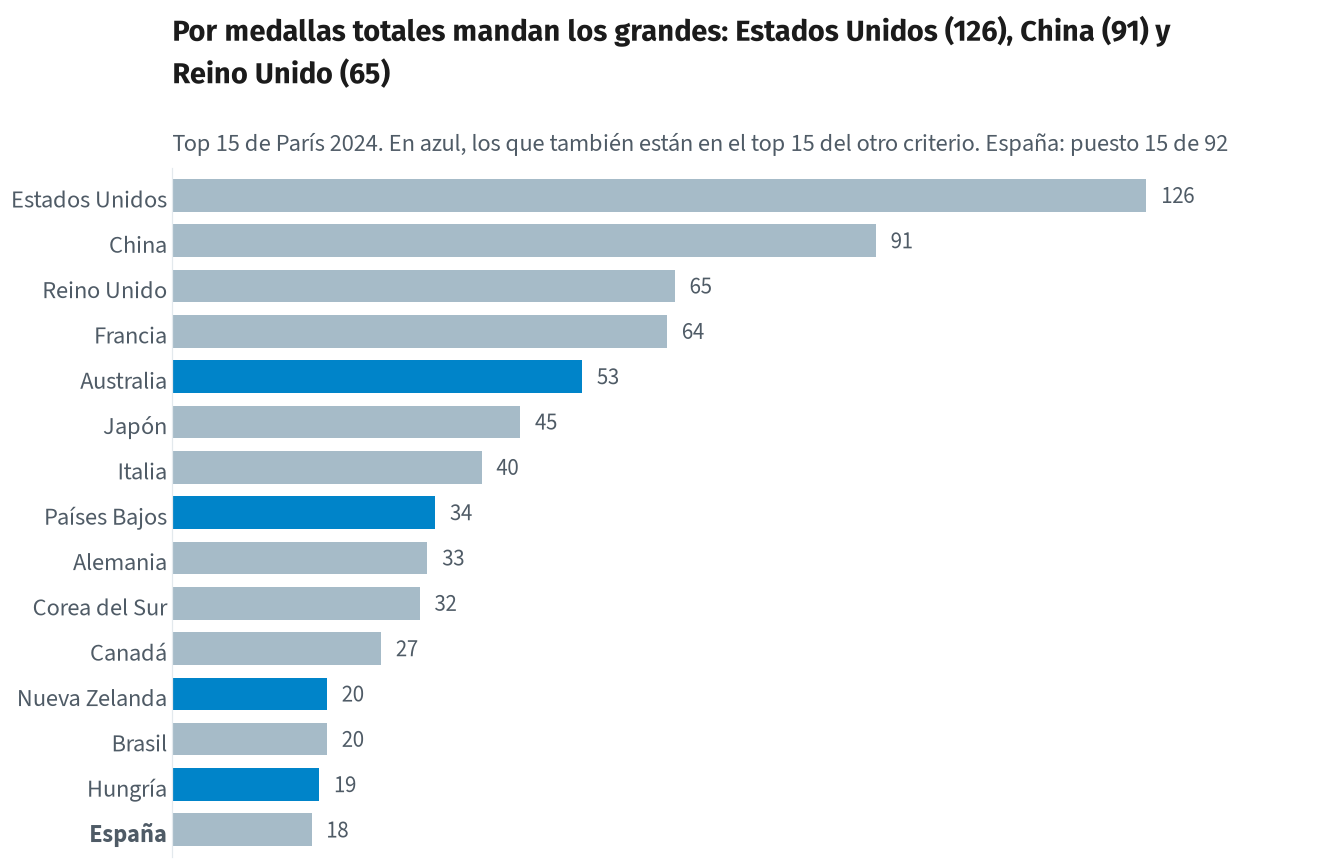

In [2]:
# El experimento: el mismo medallero, ordenado de otra forma.
criterio = widgets.ToggleButtons(
    options=[("Medallas totales", "total"), ("Por millón de habitantes", "por_millon")],
    value="total", description="Ordenar por:", style=BOTONES)
minimo = widgets.ToggleButtons(options=lab.OPCIONES_POBLACION, value=0,
                               description="Población mínima:", style=BOTONES)


def dibujar(criterio, minimo):
    lab.mostrar(lab.dibujar_medallero(medallero, minimo, criterio))


grafico = widgets.interactive_output(dibujar, {"criterio": criterio, "minimo": minimo})
display(widgets.VBox([criterio, minimo, grafico]))

## Qué observar

1. ¿Qué países están en los dos top 15 (en azul)? ¿Qué tienen en común?
2. Sin mínimo de población, ¿cuántas medallas tienen los tres primeros por habitante? ¿Qué pasaría con
   su tasa si hubieran ganado una medalla menos?
3. Sube el mínimo a 1 millón y luego a 10 millones. ¿Qué ranking es más justo? ¿Y cuál será más estable
   de unos Juegos a otros?
4. ¿Dónde queda España con cada criterio?

## Mensaje clave

> **Un total sin denominador es medio dato.**

Y una tasa con un denominador diminuto es un dato nervioso: una medalla de más o de menos lo cambia todo.

## Para curiosos

En el avanzado se ve cómo dar tasas fiables cuando el denominador es pequeño y cómo comparar territorios
de tamaños muy distintos sin que los más pequeños se queden con los dos extremos del ranking.